# Forex Currency Forecasting: end-to-end ML project

Forecast daily exchange rates for **11 currencies** (units per 1 USD): GBP, JPY, AUD, INR, PKR, QAR, KWD, CNY, RUB, EUR, CAD.

**Pipeline in this notebook**

1. Collect daily rates from an OANDA rates API
2. Clean the data and explore it (trends, returns, correlations, stationarity)
3. Hold out the last 60 days and compare 7 approaches per currency, including a naive baseline
4. Pick the best model per currency and save it for the Streamlit app (`app.py`)

**Why one model per currency?** Currencies behave very differently: pegged ones (QAR, KWD) are almost flat, floating ones (GBP, EUR) are noisy, and others (JPY, INR) drift. No single model fits all of them, so each currency gets its own winner.

## 1. Data collection

The API returns candles in a *long* format (one row per date and currency). Things worth knowing about this step:

- **Window limit.** The API key only allows 2025-04-17 to 2026-04-17, so the dataset is one year (365 daily rows). Everything downstream has to be judged with that small sample in mind.
- **Chunking.** Requests are split into 90-day chunks to keep each request small.
- **Rate used.** `average_midpoint`, the average of bid and ask, which is a fair single price for a day.
- **Wide format.** The result is pivoted to one column per currency so each currency is a ready-made time series.
- **Quote convention.** All rates are *units of currency per 1 USD*. EUR ≈ 0.86 here, the inverse of the usual EUR/USD quote of about 1.16.

In [1]:
import requests
import pandas as pd
from datetime import datetime, timedelta, timezone
import os
from pathlib import Path

# ---------- Config ----------
API_KEY = os.environ.get("OANDA_FX_KEY", "")  # never hardcode keys; see README
ENDPOINT = "https://api.corporatefxservices.com/v2/rates/candles.json"
headers = {"Authorization": f"Bearer {API_KEY}", "Accept": "application/json"}

QUOTES = ["GBP", "JPY", "AUD", "INR", "PKR", "QAR", "KWD", "CNY", "RUB", "EUR", "CAD"]

# Allowed window for this key (per the API's error message)
MIN_DATE = datetime(2025, 4, 17, tzinfo=timezone.utc)
MAX_DATE = datetime(2026, 4, 17, tzinfo=timezone.utc)

# Your requested range (clamped automatically to the allowed window)
REQ_START = datetime(2025, 4, 17, tzinfo=timezone.utc)
REQ_END = datetime(2026, 4, 17, tzinfo=timezone.utc)

# Output location (relative to the repo root)
OUT_PATH = Path("data") / "oanda_forex_timeseries.csv"

# ---------- Helpers ----------
def iso(dt):
    return dt.strftime("%Y-%m-%dT%H:%M:%S+00:00")

def fetch_chunk(start, end):
    params = {
        "base": "USD",
        "quote": QUOTES,
        "start_time": iso(start),
        "end_time": iso(end),
        "decimal_places": 6,
    }
    r = requests.get(ENDPOINT, headers=headers, params=params, timeout=60)
    if not r.ok:
        raise RuntimeError(f"{r.status_code}: {r.text[:500]}")
    return r.json()

def parse(payload):
    return [
        {
            "Date": q["start_time"][:10],
            "Currency": q["quote_currency"],
            "Rate": float(q["average_midpoint"]),
        }
        for q in payload.get("quotes", [])
        if "average_midpoint" in q
    ]

FETCH = bool(API_KEY) and not OUT_PATH.exists()
if not FETCH:
    print(f"Skipping download: using {OUT_PATH} (set OANDA_FX_KEY and delete the file to re-fetch).")
else:
    # ---------- Fetch ----------
    start = max(REQ_START, MIN_DATE)
    end = min(REQ_END, MAX_DATE)
    print(f"Fetching {start.date()} -> {end.date()}")

    all_rows = []
    cur = start
    while cur < end:
        nxt = min(cur + timedelta(days=90), end)
        all_rows += parse(fetch_chunk(cur, nxt))
        cur = nxt

    print(f"Parsed {len(all_rows)} rows")
    if not all_rows:
        raise SystemExit("No rows parsed.")

    # ---------- Pivot to wide format ----------
    df = pd.DataFrame(all_rows)
    wide = (
        df.pivot_table(index="Date", columns="Currency", values="Rate", aggfunc="last")
          .reset_index()
    )
    wide.insert(1, "USD", 1.0)
    wide = wide[[c for c in ["Date", "USD"] + QUOTES if c in wide.columns]]
    wide = wide.sort_values("Date").reset_index(drop=True)

    # ---------- Save ----------
    OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    wide.to_csv(OUT_PATH, index=False)
    print("Saved to:", OUT_PATH)

    # ---------- Sanity checks ----------
    print(wide.head())
    print("Shape:", wide.shape)
    print("Missing values per column:\n", wide.isna().sum())
    print("Date range:", wide["Date"].min(), "->", wide["Date"].max())
    print("Duplicate dates:", wide.duplicated("Date").sum())


Fetching 2025-04-17 -> 2026-04-17
Parsed 4015 rows
Saved to: data/oanda_forex_timeseries.csv
Currency        Date  USD       GBP         JPY       AUD        INR  \
0         2025-04-17  1.0  0.755185  142.512780  1.570180  85.463210   
1         2025-04-18  1.0  0.753080  142.287953  1.568283  85.400216   
2         2025-04-19  1.0  0.752112  142.173000  1.568344  85.378128   
3         2025-04-20  1.0  0.752096  142.121849  1.568220  85.378478   
4         2025-04-21  1.0  0.747242  140.816938  1.558729  85.163930   

Currency         PKR       QAR       KWD       CNY        RUB       EUR  \
0         280.443594  3.642906  0.306653  7.300934  82.374184  0.879817   
1         280.854856  3.644001  0.306620  7.299822  82.070744  0.878589   
2         280.869086  3.645600  0.306628  7.298743  82.153018  0.877582   
3         280.864882  3.645522  0.306623  7.298786  82.110108  0.877284   
4         280.924088  3.643848  0.306336  7.293787  81.143604  0.868394   

Currency       CAD  
0 

## 2. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.figsize"] = (12, 5)

## 3. Load and inspect

Before any modeling we check the basics: shape, types, missing values and duplicates. Bad data caught here is far cheaper to fix than bad forecasts found later.

In [2]:
df = pd.read_csv("data/oanda_forex_timeseries.csv")
df.head()

,Date,USD,GBP,JPY,AUD,INR,PKR,QAR,KWD,CNY,RUB,EUR,CAD
0,2025-04-17,1.0000,0.7552,142.5128,1.5702,85.4632,280.4436,3.6429,0.3067,7.3009,82.3742,0.8798,1.3866
1,2025-04-18,1.0000,0.7531,142.2880,1.5683,85.4002,280.8549,3.6440,0.3066,7.2998,82.0707,0.8786,1.3855
2,2025-04-19,1.0000,0.7521,142.1730,1.5683,85.3781,280.8691,3.6456,0.3066,7.2987,82.1530,0.8776,1.3849
3,2025-04-20,1.0000,0.7521,142.1218,1.5682,85.3785,280.8649,3.6455,0.3066,7.2988,82.1101,0.8773,1.3848
4,2025-04-21,1.0000,0.7472,140.8169,1.5587,85.1639,280.9241,3.6438,0.3063,7.2938,81.1436,0.8684,1.3814


In [3]:
print(df.shape)
df.info()

(365, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    365 non-null    object 
 1   USD     365 non-null    float64
 2   GBP     365 non-null    float64
 3   JPY     365 non-null    float64
 4   AUD     365 non-null    float64
 5   INR     365 non-null    float64
 6   PKR     365 non-null    float64
 7   QAR     365 non-null    float64
 8   KWD     365 non-null    float64
 9   CNY     365 non-null    float64
 10  RUB     365 non-null    float64
 11  EUR     365 non-null    float64
 12  CAD     365 non-null    float64
dtypes: float64(12), object(1)
memory usage: 37.2+ KB


In [4]:
display(df.describe().T)
print("Missing values:\n", df.isna().sum())
print("Duplicate dates:", df["Date"].duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
USD,365.0000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
GBP,365.0000,0.7452,0.0082,0.7241,0.7399,0.7445,0.7504,0.7672
JPY,365.0000,151.3173,5.4653,140.8169,147.0676,151.5852,156.3093,160.3171
AUD,365.0000,1.5055,0.0483,1.3943,1.4904,1.5254,1.5396,1.5702
INR,365.0000,88.6721,2.4911,84.2803,86.3787,88.6603,90.5316,94.6284
PKR,365.0000,281.5298,1.6165,278.6792,280.0500,281.6714,282.7920,285.4420
QAR,365.0000,3.6444,0.0037,3.6300,3.6418,3.6440,3.6463,3.6594
KWD,365.0000,0.3066,0.0009,0.3050,0.3058,0.3066,0.3071,0.3094
CNY,365.0000,7.0829,0.1219,6.8180,6.9711,7.1203,7.1779,7.3032
RUB,365.0000,79.7388,2.0336,75.4097,78.4070,79.7555,81.0828,85.2723


Missing values:
 Date    0
USD     0
GBP     0
JPY     0
AUD     0
INR     0
PKR     0
QAR     0
KWD     0
CNY     0
RUB     0
EUR     0
CAD     0
dtype: int64
Duplicate dates: 0


**What we see:** 365 rows × 13 columns (a date column, `USD` and 11 currencies), no missing values, no duplicate dates. The `describe()` table already tells a story: `USD` has zero spread (it is the base currency, always 1.0), pegged currencies barely move (QAR std 0.0037 around 3.644, KWD std 0.0009 around 0.307), while JPY spans about 141 to 160.

## 4. Cleaning

- Convert `Date` to a real datetime and use it as the index, which time-series models require.
- Sort and de-duplicate so the series is strictly chronological.
- Check for gaps against a full daily calendar. This dataset includes **weekends**, so the frequency is calendar-daily (`"D"`), not business-daily. Using the wrong frequency would silently create or drop dates.
- Forward-fill as a safeguard. It does nothing here (no gaps), but keeps the notebook working on future data that might have holes.

In [5]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").drop_duplicates("Date").set_index("Date")

full_range = pd.date_range(df.index.min(), df.index.max(), freq="D")
print("Rows:", len(df), "| Expected daily rows:", len(full_range))
print("Missing dates:", full_range.difference(df.index).tolist())

df = df.asfreq("D").ffill()      # no-op if there are no gaps
df.index.freq, df.isna().sum().sum()

Rows: 365 | Expected daily rows: 365
Missing dates: []


(<Day>, np.int64(0))

## 5. Exploratory visualizations

Currencies live on very different scales (JPY ≈ 150, KWD ≈ 0.3), so raw lines on one axis are unreadable. **Rebasing** every series to 100 at the start makes relative movement directly comparable. Over this year, JPY rose about 12% and INR about 9%, while AUD fell about 11%, RUB about 8% and CNY about 7%. QAR, PKR and KWD stayed within about 1%.

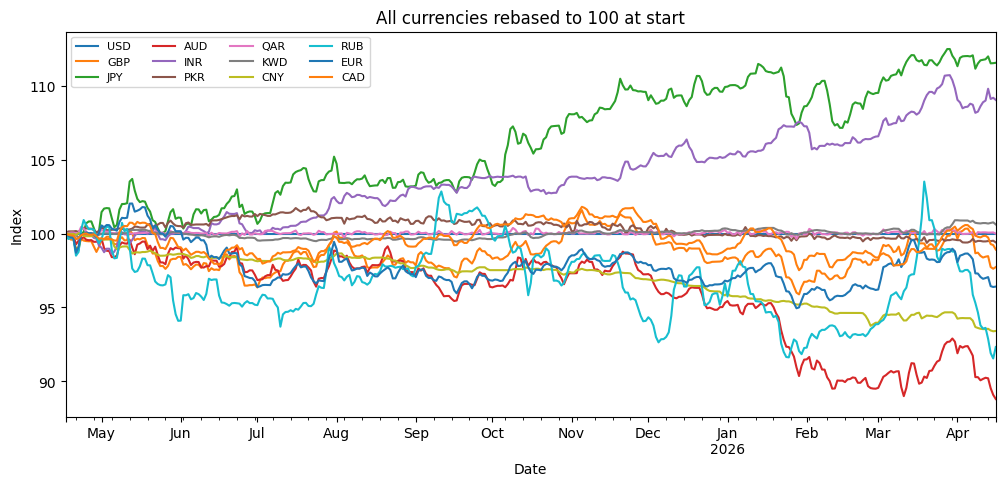

In [6]:
rebased = df / df.iloc[0] * 100
rebased.plot(title="All currencies rebased to 100 at start")
plt.ylabel("Index"); plt.legend(ncol=4, fontsize=8); plt.show()

The 30-day rolling mean smooths daily noise so the underlying direction is visible. It shows which currencies *trend* (useful for models with a trend component) and which are flat or mean-reverting.

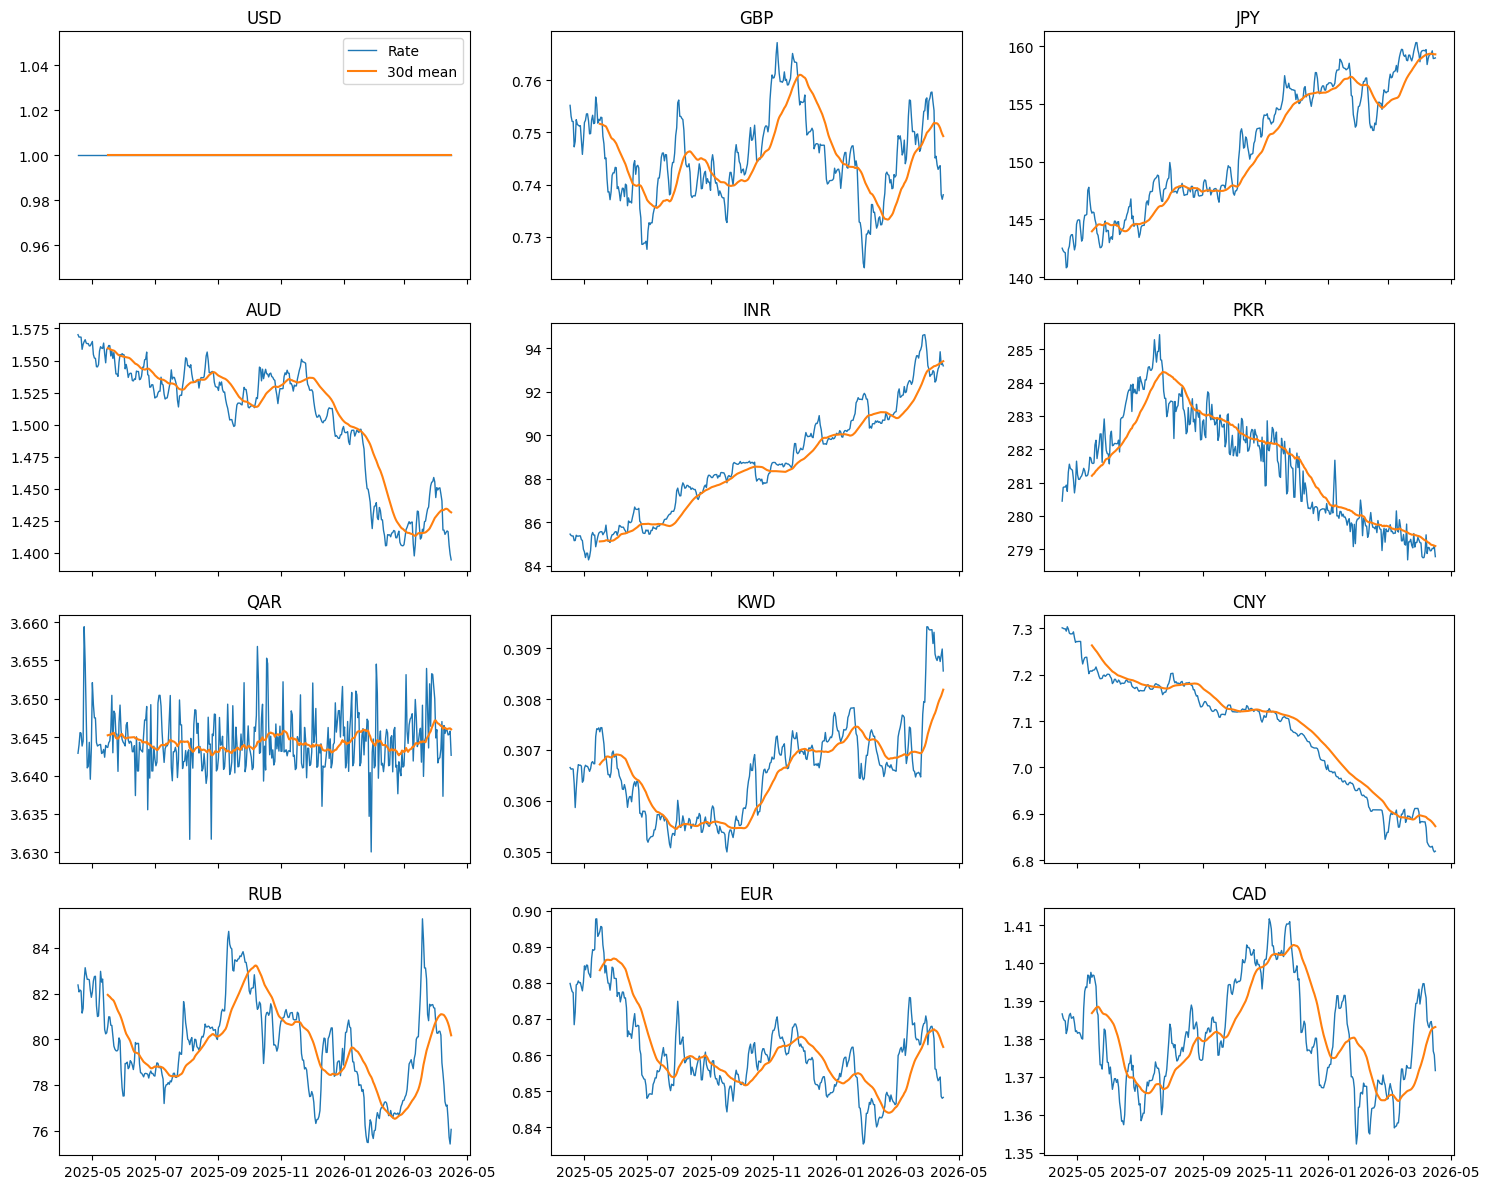

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12), sharex=True)
for ax, col in zip(axes.flat, df.columns):
    ax.plot(df[col], lw=1, label="Rate")
    ax.plot(df[col].rolling(30).mean(), lw=1.5, label="30d mean")
    ax.set_title(col)
axes.flat[0].legend(); plt.tight_layout(); plt.show()

## 6. Returns and correlations

We use **daily percentage returns**, not raw rates, for correlation. Two currencies that both trend upward will look highly correlated on raw rates even if they are unrelated (spurious correlation). Returns remove that effect.

In [8]:
returns = df.pct_change().dropna()
returns.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
USD,0.0000,0.0000,0.0000,0.0000
GBP,-0.0001,0.0028,-0.0121,0.0078
JPY,0.0003,0.0038,-0.0124,0.0164
AUD,-0.0003,0.0035,-0.0158,0.0113
INR,0.0002,0.0021,-0.0105,0.0082
PKR,-0.0000,0.0014,-0.0044,0.0069
QAR,0.0000,0.0012,-0.0037,0.0041
KWD,0.0000,0.0006,-0.0023,0.0027
CNY,-0.0002,0.0009,-0.0047,0.0027
RUB,-0.0002,0.0057,-0.0187,0.0244


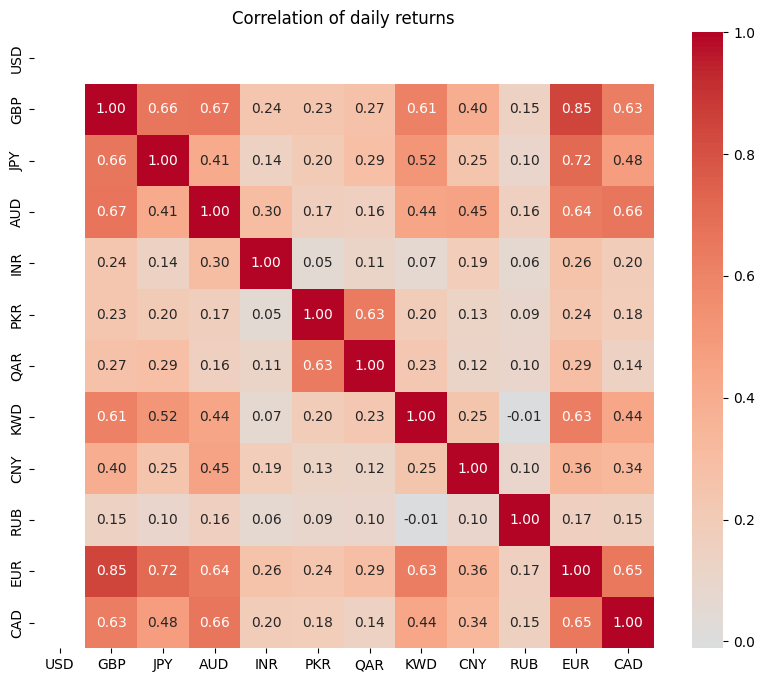

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(returns.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of daily returns"); plt.show()

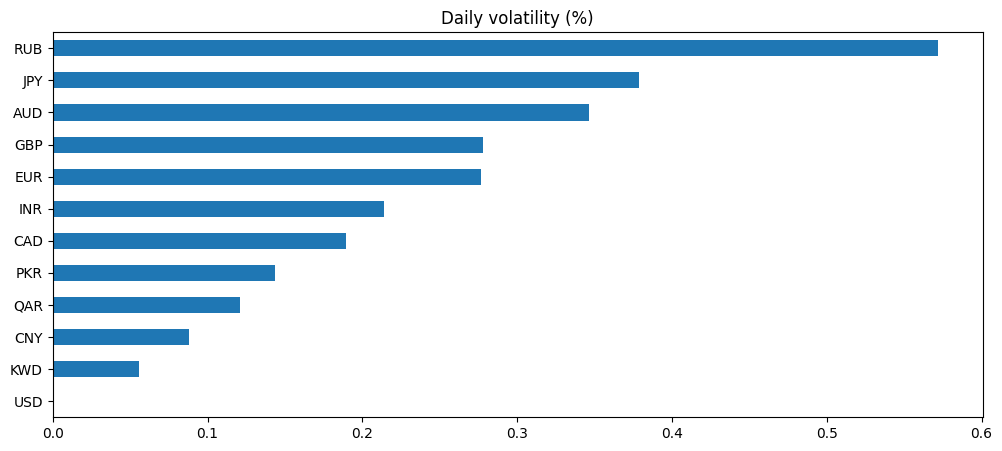

In [10]:
vol = (returns.std() * 100).sort_values()
vol.plot.barh(title="Daily volatility (%)"); plt.show()

**What we see**

- **Strong co-movement among major currencies.** EUR–GBP is the highest at 0.85, followed by EUR–JPY at 0.72 and GBP–AUD at 0.67. These all react strongly to broad USD moves.
- **Pegged currencies link to the dollar's behavior.** PKR–QAR correlate at 0.63. KWD (tied to a currency basket) correlates 0.63 with EUR and 0.61 with GBP.
- **RUB and INR are largely independent.** RUB correlates at most 0.17 with anything and INR at most 0.30, consistent with managed and policy-driven pricing.
- **Volatility ranking** (std of daily returns): RUB 0.57% > JPY 0.38% > AUD 0.35% > GBP and EUR 0.28% > INR 0.21% > CAD 0.19% > PKR 0.14% > QAR 0.12% > CNY 0.09% > KWD 0.06%.

**Dropping `USD`.** The base currency is constant (always 1.0). It has no information to forecast and breaks tests such as ADF (`x is constant`), so it is removed before modeling.

In [11]:
df = df.drop(columns="USD", errors="ignore")
returns = df.pct_change().dropna()   # rebuild returns without it
df.shape

(365, 11)

## 7. Stationarity (ADF test)

Many models (ARIMA family) assume a series without a trend. The **Augmented Dickey-Fuller** test checks this: a p-value below 0.05 suggests the series is stationary. We test both the rates (*levels*) and the returns.

In [12]:
from statsmodels.tsa.stattools import adfuller

rows = []
for col in df.columns:
    p_level = adfuller(df[col])[1]
    p_ret = adfuller(returns[col])[1]
    rows.append({"currency": col, "p_levels": p_level, "p_returns": p_ret,
                 "levels_stationary": p_level < 0.05, "returns_stationary": p_ret < 0.05})
adf_df = pd.DataFrame(rows).set_index("currency")
adf_df.style.format({"p_levels": "{:.4f}", "p_returns": "{:.4f}"})

,p_levels,p_returns,levels_stationary,returns_stationary
currency,,,,
GBP,0.0484,0.0000,True,True
JPY,0.7990,0.0000,False,True
AUD,0.8815,0.0000,False,True
INR,0.8862,0.0000,False,True
PKR,0.9394,0.0000,False,True
QAR,0.0000,0.0000,True,True
KWD,0.7488,0.0000,False,True
CNY,0.9831,0.0000,False,True
RUB,0.1413,0.0000,False,True


**What we see:** the *levels* are non-stationary for most currencies (p between 0.11 and 0.98). Only QAR (a peg, so essentially flat) and GBP (p = 0.048, borderline) pass. The *returns* are stationary for every currency (p ≈ 0).

**Reasoning that follows from this**

- ARIMA/SARIMA use differencing (`d = 1`), which is the same idea as modeling returns.
- The tree models (XGBoost, LightGBM) and the LSTM are trained on **returns**, not prices, so their inputs are stationary.
- With only 365 points the test has limited power, so we treat p-values near 0.05 as inconclusive.

## 8. Train/test split

The last **60 days** are held out. The split is **chronological, never shuffled**: shuffling would let the model see the future and give falsely good scores.

- Train: 2025-04-17 → 2026-02-15 (305 days)
- Test: 2026-02-16 → 2026-04-16 (60 days)

In [13]:
TEST_DAYS = 60
train, test = df.iloc[:-TEST_DAYS], df.iloc[-TEST_DAYS:]

print("Train:", train.index.min().date(), "->", train.index.max().date(), f"({len(train)} days)")
print("Test: ", test.index.min().date(),  "->", test.index.max().date(),  f"({len(test)} days)")

Train: 2025-04-17 -> 2026-02-15 (305 days)
Test:  2026-02-16 -> 2026-04-16 (60 days)


## 9. Metrics

- **MAE** is the average absolute error, in the currency's own units.
- **RMSE** is like MAE but penalizes big misses more. It is our main selection metric.
- **MAPE** is the error as a percentage, so it is the only one comparable *across* currencies.

MAE and RMSE should only be compared across models *for the same currency* (a JPY error of 2.6 and a KWD error of 0.001 are not comparable).

In [14]:
def evaluate(actual, pred):
    actual, pred = np.asarray(actual), np.asarray(pred)
    err = actual - pred
    return {
        "MAE": np.abs(err).mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "MAPE": (np.abs(err / actual)).mean() * 100,
    }

results = []   # every model we try appends rows here

def log_result(currency, model, actual, pred):
    results.append({"currency": currency, "model": model, **evaluate(actual, pred)})

## 10. Naive baseline

The naive forecast is "tomorrow = last known value", a flat line. Exchange rates are close to a random walk, so this is a genuinely hard baseline to beat. **Any model that cannot beat it adds no value.** Every later result is judged against it.

In [15]:
for col in df.columns:
    naive_pred = np.repeat(train[col].iloc[-1], len(test))
    log_result(col, "naive", test[col], naive_pred)

res = pd.DataFrame(results)
res[res.model == "naive"].set_index("currency").round(4)

,model,MAE,RMSE,MAPE
currency,,,,
GBP,naive,0.0148,0.0160,1.9716
JPY,naive,5.3560,5.6622,3.3752
AUD,naive,0.0136,0.0189,0.9482
INR,naive,1.9142,2.2244,2.0553
PKR,naive,0.3788,0.4665,0.1357
QAR,naive,0.0043,0.0054,0.1179
KWD,naive,0.0010,0.0014,0.3096
CNY,naive,0.0263,0.0379,0.3834
RUB,naive,2.5609,3.3781,3.1595


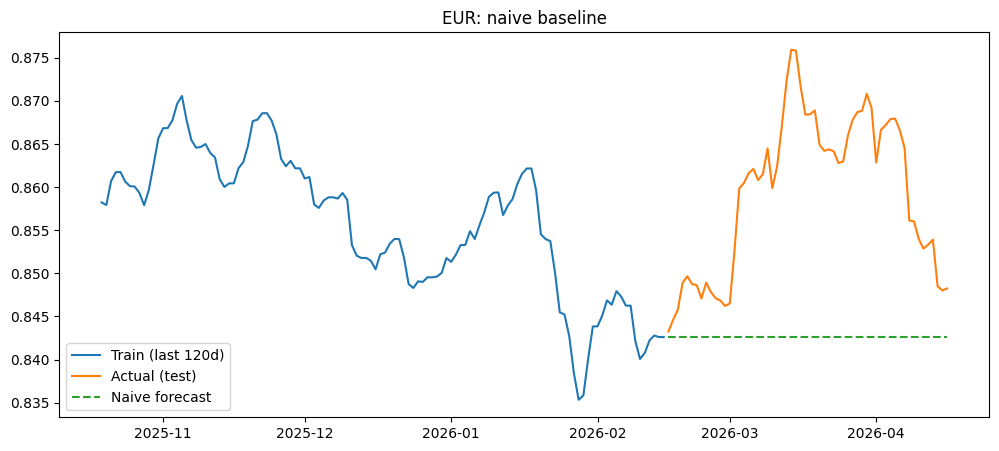

In [16]:
col = "EUR"
plt.plot(train[col].iloc[-120:], label="Train (last 120d)")
plt.plot(test[col], label="Actual (test)")
plt.plot(test.index, np.repeat(train[col].iloc[-1], len(test)), "--", label="Naive forecast")
plt.title(f"{col}: naive baseline"); plt.legend(); plt.show()

## 11. Models compared

All models forecast the full 60-day horizon from the training data.

| Model | Idea | Why included |
|---|---|---|
| **ARIMA(1,1,1)** | Statistical model on differenced data | Classic baseline; handles trend through differencing |
| **SARIMA(1,1,1)(1,0,1,7)** | ARIMA plus weekly seasonality | The data includes weekends, so a 7-day pattern is plausible |
| **Prophet** | Piecewise-linear trend + seasonality | Good at drifting series; robust to missing data |
| **XGBoost** and **LightGBM** | Gradient-boosted trees on the last 10 daily returns + day of week | Capture non-linear patterns; forecast recursively (each prediction feeds the next) |
| **LSTM** | Neural net on a 14-day window of standardized returns | Deep-learning approach to sequences |

**Design choices:** tree models and the LSTM predict *returns*, then rebuild prices from the last known value. This keeps inputs stationary and puts every currency on the same scale. Hyperparameters are deliberately modest and **not tuned**, because with 305 training points heavy tuning would mostly overfit.

In [17]:
import logging, time, warnings
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
H, LAGS = len(test), 10

def arima_forecast(s, h):
    return ARIMA(s.values, order=(1, 1, 1)).fit().forecast(h)

def sarima_forecast(s, h):   # weekly seasonality (period 7)
    m = SARIMAX(s.values, order=(1, 1, 1), seasonal_order=(1, 0, 1, 7),
                enforce_stationarity=False, enforce_invertibility=False)
    return m.fit(disp=False).forecast(h)

def prophet_forecast(s, h):
    from prophet import Prophet
    m = Prophet(daily_seasonality=False)
    m.fit(pd.DataFrame({"ds": s.index, "y": s.values}))
    future = pd.date_range(s.index[-1] + pd.Timedelta(days=1), periods=h)
    return m.predict(pd.DataFrame({"ds": future}))["yhat"].values

def gbm_forecast(make_model, s, h):
    """Boosted trees on lagged returns + day-of-week, forecasting recursively."""
    r = s.pct_change().dropna()
    X = np.array([np.append(r.values[i-LAGS:i], r.index[i].dayofweek) for i in range(LAGS, len(r))])
    m = make_model().fit(X, r.values[LAGS:])
    hist, price, out = list(r.values[-LAGS:]), s.iloc[-1], []
    for d in pd.date_range(s.index[-1] + pd.Timedelta(days=1), periods=h):
        x = np.append(hist[-LAGS:], d.dayofweek).reshape(1, -1)
        ret = float(m.predict(x)[0]); price *= 1 + ret; out.append(price); hist.append(ret)
    return np.array(out)

xgb_forecast = lambda s, h: gbm_forecast(
    lambda: XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05), s, h)
lgbm_forecast = lambda s, h: gbm_forecast(
    lambda: LGBMRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, verbose=-1), s, h)

def lstm_forecast(s, h, window=14, epochs=30):
    import tensorflow as tf
    tf.keras.utils.set_random_seed(42)
    r = s.pct_change().dropna().values
    mu, sd = r.mean(), r.std()
    z = (r - mu) / sd
    X = np.array([z[i-window:i] for i in range(window, len(z))])[..., None]
    model = tf.keras.Sequential([tf.keras.layers.Input((window, 1)),
                                 tf.keras.layers.LSTM(32), tf.keras.layers.Dense(1)])
    model.compile("adam", "mse")
    model.fit(X, z[window:], epochs=epochs, batch_size=16, verbose=0)
    hist, price, out = list(z[-window:]), s.iloc[-1], []
    for _ in range(h):
        n = float(model(np.array(hist[-window:]).reshape(1, window, 1), training=False)[0, 0])
        hist.append(n); price *= 1 + (n * sd + mu); out.append(price)
    return np.array(out)

models = {"arima": arima_forecast, "sarima": sarima_forecast, "prophet": prophet_forecast,
          "xgboost": xgb_forecast, "lightgbm": lgbm_forecast, "lstm": lstm_forecast}

## 12. Train and evaluate every model on every currency

One loop runs all models for all currencies. Failures are caught and printed instead of stopping the run (none occurred).

In [18]:
results = [r for r in results if r["model"] == "naive"]   # keep baseline, avoid duplicates on re-run
forecasts = {}

for col in df.columns:
    for name, fn in models.items():
        t0 = time.time()
        try:
            pred = np.asarray(fn(train[col], H), dtype=float)
            forecasts[(col, name)] = pred
            log_result(col, name, test[col], pred)
            print(f"{col:4s} {name:9s} ok  {time.time()-t0:5.1f}s")
        except Exception as e:
            print(f"{col:4s} {name:9s} FAILED: {e}")

18:05:31 - cmdstanpy - INFO - Chain [1] start processing


GBP  arima     ok    0.1s
GBP  sarima    ok    0.0s


18:05:32 - cmdstanpy - INFO - Chain [1] done processing


GBP  prophet   ok    0.7s
GBP  xgboost   ok    0.2s
GBP  lightgbm  ok    0.2s
GBP  lstm      ok   13.4s
JPY  arima     ok    0.1s
JPY  sarima    ok    0.2s


18:05:46 - cmdstanpy - INFO - Chain [1] start processing
18:05:46 - cmdstanpy - INFO - Chain [1] done processing


...

EUR  prophet   ok    0.1s
EUR  xgboost   ok    0.2s
EUR  lightgbm  ok    0.2s


18:06:34 - cmdstanpy - INFO - Chain [1] start processing


EUR  lstm      ok    4.4s
CAD  arima     ok    0.0s
CAD  sarima    ok    0.1s


18:06:34 - cmdstanpy - INFO - Chain [1] done processing


CAD  prophet   ok    0.2s
CAD  xgboost   ok    0.2s
CAD  lightgbm  ok    0.2s
CAD  lstm      ok    4.3s


The tables below show RMSE and MAPE for every currency × model. Lower is better.

In [19]:
res = pd.DataFrame(results)
print("RMSE by currency x model (lower is better)")
display(res.pivot(index="currency", columns="model", values="RMSE").round(5))
print("MAPE (%) by currency x model")
display(res.pivot(index="currency", columns="model", values="MAPE").round(3))

RMSE by currency x model (lower is better)


model,arima,lightgbm,lstm,naive,prophet,sarima,xgboost
currency,,,,,,,
AUD,0.0189,0.0228,0.0237,0.0189,0.0626,0.0187,0.0234
CAD,0.0166,0.0156,0.0112,0.0167,0.0217,0.0165,0.0124
CNY,0.0377,0.0355,0.0525,0.0379,0.0493,0.0357,0.0341
EUR,0.0191,0.0153,0.0225,0.0191,0.0235,0.0187,0.0192
GBP,0.0158,0.0095,0.0284,0.0160,0.0259,0.0157,0.0161
INR,2.2209,2.2487,1.2065,2.2244,1.1903,2.2025,2.4420
JPY,5.6264,2.9522,2.5993,5.6622,3.9710,4.9934,3.8054
KWD,0.0014,0.0011,0.0014,0.0014,0.0013,0.0013,0.0014
PKR,0.5139,1.1240,1.3666,0.4665,0.2314,0.4888,1.5677


MAPE (%) by currency x model


model,arima,lightgbm,lstm,naive,prophet,sarima,xgboost
currency,,,,,,,
AUD,0.9470,1.2240,1.2110,0.9480,3.5770,0.9340,1.1380
CAD,0.9650,0.9120,0.7420,0.9680,1.2210,0.9520,0.7260
CNY,0.3810,0.4150,0.6600,0.3830,0.6120,0.3570,0.3980
EUR,1.9390,1.4660,2.3500,1.9420,2.4200,1.8940,1.9800
GBP,1.9410,1.1560,3.5180,1.9720,3.2410,1.9280,1.9590
INR,2.0510,2.0030,1.0020,2.0550,1.0310,2.0270,2.2120
JPY,3.3510,1.6870,1.4760,3.3750,2.2460,2.9470,2.1790
KWD,0.3100,0.2790,0.3240,0.3100,0.3040,0.3010,0.3100
PKR,0.1530,0.3420,0.4170,0.1360,0.0600,0.1440,0.4590


**What we see**

- **ARIMA is essentially the naive forecast** (for example EUR RMSE 0.0191 for both). With no strong autocorrelation, ARIMA(1,1,1) collapses to a random walk. SARIMA edges ahead only on AUD and QAR.
- **Prophet is the most uneven.** It is the best for INR (1.19 vs 2.22 naive) and PKR (0.23 vs 0.47), where the series drift steadily, but the worst for AUD (0.063 vs 0.019), where its extrapolated trend likely points the wrong way.
- **LightGBM and XGBoost win on most majors.** LightGBM is best for GBP, EUR and KWD, and XGBoost for CNY and RUB.
- **LSTM is inconsistent.** It is best for CAD and JPY but among the worst for GBP (0.028 vs 0.016 naive). We would not trust it on 305 training points.

## 13. Choosing the best model per currency

The winner per currency is the model with the **lowest RMSE** on the test window. `improvement_vs_naive_%` shows how much better it is than the flat baseline. A gain of only a percent or two (AUD, 1.1%) is effectively a tie.

In [20]:
best = res.loc[res.groupby("currency").RMSE.idxmin()].set_index("currency")
naive = res[res.model == "naive"].set_index("currency")

summary = pd.DataFrame({
    "best_model": best.model,
    "MAE": best.MAE, "RMSE": best.RMSE, "MAPE_%": best.MAPE,
    "naive_RMSE": naive.RMSE,
    "improvement_vs_naive_%": (1 - best.RMSE / naive.RMSE) * 100,
})
summary["beats_naive"] = summary.best_model != "naive"
summary.round(4)

,best_model,MAE,RMSE,MAPE_%,naive_RMSE,improvement_vs_naive_%,beats_naive
currency,,,,,,,
AUD,sarima,0.0134,0.0187,0.9343,0.0189,1.1013,True
CAD,lstm,0.0102,0.0113,0.7422,0.0167,32.4865,True
CNY,xgboost,0.0274,0.0341,0.3980,0.0379,10.1386,True
EUR,lightgbm,0.0127,0.0153,1.4660,0.0191,19.9854,True
GBP,lightgbm,0.0087,0.0095,1.1564,0.0160,40.5896,True
INR,prophet,0.9611,1.1903,1.0313,2.2244,46.4902,True
JPY,lstm,2.3438,2.5993,1.4757,5.6622,54.0938,True
KWD,lightgbm,0.0009,0.0011,0.2795,0.0014,17.9661,True
PKR,prophet,0.1679,0.2314,0.0601,0.4665,50.3986,True


## 14. Test graphs: actual vs predicted

These graphs use predictions from models trained **without** the last 60 days, so this is an honest comparison against what actually happened. A good forecast starts near the actual line and tracks its direction. A line that is almost identical to the naive baseline means the model adds little.

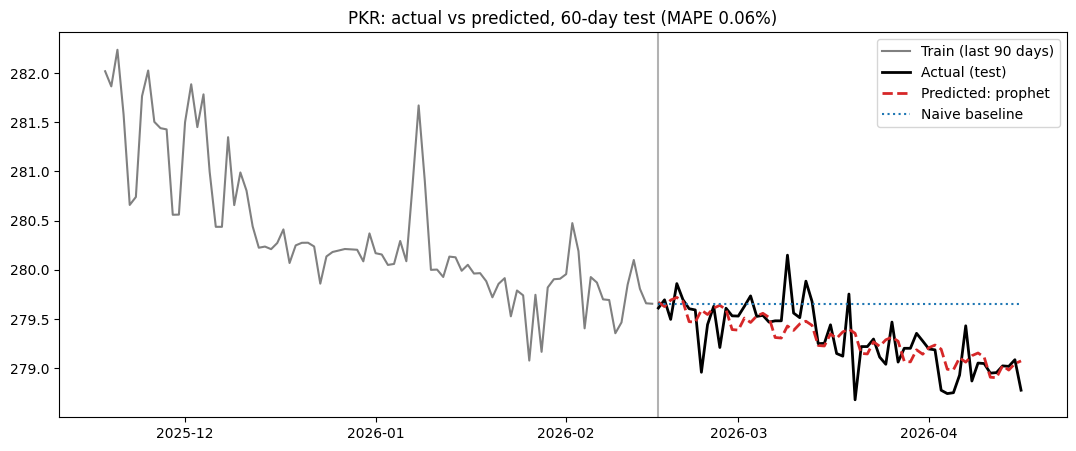

In [21]:
def get_pred(c, model):
    return np.repeat(train[c].iloc[-1], len(test)) if model == "naive" else forecasts[(c, model)]

c = "PKR"                                   # change to any currency
m = best.model[c]
mape = res[(res.currency == c) & (res.model == m)].MAPE.iloc[0]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train[c].iloc[-90:], color="gray", label="Train (last 90 days)")
ax.plot(test[c], color="black", lw=2, label="Actual (test)")
ax.plot(test.index, get_pred(c, m), "--", color="tab:red", lw=2, label=f"Predicted: {m}")
ax.plot(test.index, get_pred(c, "naive"), ":", color="tab:blue", label="Naive baseline")
ax.axvline(test.index[0], color="k", alpha=0.3)
ax.set_title(f"{c}: actual vs predicted, 60-day test (MAPE {mape:.2f}%)"); ax.legend(); plt.show()

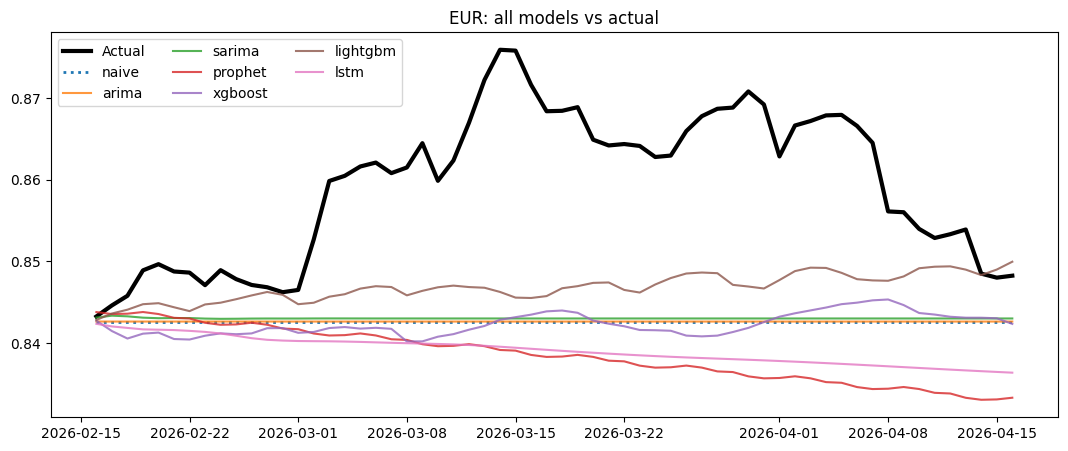

In [22]:
c = "EUR"
plt.figure(figsize=(13, 5))
plt.plot(test[c], "k", lw=3, label="Actual")
plt.plot(test.index, get_pred(c, "naive"), ":", lw=2, label="naive")
for name in models:
    if (c, name) in forecasts:
        plt.plot(test.index, forecasts[(c, name)], alpha=0.8, label=name)
plt.title(f"{c}: all models vs actual"); plt.legend(ncol=3); plt.show()

## 15. Saving models for the app

**Deployable models only.** The Streamlit app can rebuild predictions for naive, ARIMA, SARIMA, Prophet, XGBoost and LightGBM. It cannot serve the LSTM without adding TensorFlow to the Docker image, so where LSTM won (CAD, JPY) we deploy the best of the others (XGBoost and LightGBM respectively).

**Refit on all the data.** Each winner is refit on the full history (including the test window) before saving, so the app's forecasts start from the most recent data. Because of this, the test metrics describe the train-only version of each model.

**Artifact format.** Each model is saved as a plain dict (`kind`, `model`, `last_date`, `tail`) so `app.py` can load it without importing any custom classes. `predict_artifact` here and `predict` in `app.py` must stay identical.

In [23]:
import joblib, os

def fit_final(kind, s):
    m = None
    if kind == "arima":
        m = ARIMA(s.values, order=(1, 1, 1)).fit()
    elif kind == "sarima":
        m = SARIMAX(s.values, order=(1, 1, 1), seasonal_order=(1, 0, 1, 7),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    elif kind == "prophet":
        from prophet import Prophet
        m = Prophet(daily_seasonality=False)
        m.fit(pd.DataFrame({"ds": s.index, "y": s.values}))
    elif kind in ("xgboost", "lightgbm"):
        r = s.pct_change().dropna()
        X = np.array([np.append(r.values[i-LAGS:i], r.index[i].dayofweek) for i in range(LAGS, len(r))])
        mk = (lambda: XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05)) if kind == "xgboost" \
             else (lambda: LGBMRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, verbose=-1))
        m = mk().fit(X, r.values[LAGS:])
    elif kind != "naive":
        raise ValueError(f"{kind} is not supported by the app")
    return {"kind": kind, "model": m, "last_date": s.index[-1], "tail": s.iloc[-(LAGS + 1):]}

def predict_artifact(a, h):
    idx = pd.date_range(a["last_date"] + pd.Timedelta(days=1), periods=h)
    k, last = a["kind"], a["tail"].iloc[-1]
    if k == "naive":
        v = np.repeat(last, h)
    elif k in ("arima", "sarima"):
        v = a["model"].forecast(h)
    elif k == "prophet":
        v = a["model"].predict(pd.DataFrame({"ds": idx}))["yhat"].values
    else:
        r, v, p = list(a["tail"].pct_change().dropna().values[-LAGS:]), [], last
        for d in idx:
            x = np.append(r[-LAGS:], d.dayofweek).reshape(1, -1)
            n = float(a["model"].predict(x)[0]); p *= 1 + n; v.append(p); r.append(n)
    return pd.Series(np.asarray(v, dtype=float), index=idx)

DEPLOYABLE = ["naive", "arima", "sarima", "prophet", "xgboost", "lightgbm"]

Select the best deployable model per currency and print a note where the overall winner can't be served by the app.

In [24]:
dep = res[res.model.isin(DEPLOYABLE)]
best_dep = dep.loc[dep.groupby("currency").RMSE.idxmin()].set_index("currency")
for c in best_dep.index:
    if best.model[c] != best_dep.model[c]:
        print(f"{c}: overall best is {best.model[c]} (app can't serve it), using {best_dep.model[c]}")
best_dep[["model", "MAE", "RMSE", "MAPE"]].round(4)

CAD: overall best is lstm (app can't serve it), using xgboost
JPY: overall best is lstm (app can't serve it), using lightgbm


,model,MAE,RMSE,MAPE
currency,,,,
AUD,sarima,0.0134,0.0187,0.9343
CAD,xgboost,0.0100,0.0124,0.7260
CNY,xgboost,0.0274,0.0341,0.3980
EUR,lightgbm,0.0127,0.0153,1.4660
GBP,lightgbm,0.0087,0.0095,1.1564
INR,prophet,0.9611,1.1903,1.0313
JPY,lightgbm,2.6803,2.9522,1.6875
KWD,lightgbm,0.0009,0.0011,0.2795
PKR,prophet,0.1679,0.2314,0.0601


Refit each chosen model on all data and write everything the app reads: `models/*.pkl`, `models/results.csv` (the comparison table) and `data/forex_data.csv` (clean history).

In [25]:
os.makedirs("models", exist_ok=True); os.makedirs("data", exist_ok=True)
for c, row in best_dep.iterrows():
    joblib.dump(fit_final(row.model, df[c]), f"models/{c}_model.pkl")
    print(f"saved models/{c}_model.pkl ({row.model})")

df.to_csv("data/forex_data.csv")        # index is named "date"
dep.rename(columns={"currency": "pair"}).round(6).to_csv("models/results.csv", index=False)

saved models/AUD_model.pkl (sarima)
saved models/CAD_model.pkl (xgboost)
saved models/CNY_model.pkl (xgboost)
saved models/EUR_model.pkl (lightgbm)


18:07:07 - cmdstanpy - INFO - Chain [1] start processing
18:07:08 - cmdstanpy - INFO - Chain [1] done processing


saved models/GBP_model.pkl (lightgbm)
saved models/INR_model.pkl (prophet)


18:07:08 - cmdstanpy - INFO - Chain [1] start processing


saved models/JPY_model.pkl (lightgbm)
saved models/KWD_model.pkl (lightgbm)


18:07:08 - cmdstanpy - INFO - Chain [1] done processing


saved models/PKR_model.pkl (prophet)
saved models/QAR_model.pkl (sarima)
saved models/RUB_model.pkl (xgboost)


Sanity check: reload a saved model the way the app does and plot a 30-day forecast. It should start the day after the last data point and look plausible next to the history.

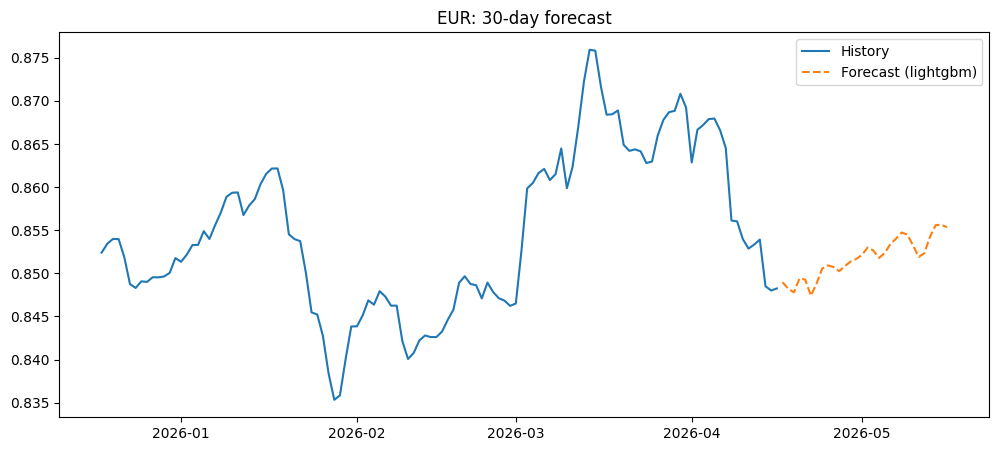

In [26]:
c = "EUR"
art = joblib.load(f"models/{c}_model.pkl")
fc = predict_artifact(art, 30)
plt.plot(df[c].iloc[-120:], label="History"); plt.plot(fc, "--", label=f"Forecast ({art['kind']})")
plt.title(f"{c}: 30-day forecast"); plt.legend(); plt.show()

## 16. Conclusions and limitations

**Conclusions**

- Every currency's selected model beat the naive baseline on the test window, by roughly 1% (AUD) to about 50% (PKR).
- No single model type wins everywhere: Prophet for steadily drifting INR and PKR, SARIMA for AUD and QAR, LightGBM for GBP, EUR, KWD and JPY, XGBoost for CAD, CNY and RUB.
- ARIMA is indistinguishable from naive, which is what you'd expect from near-random-walk data.

**Limitations (please read before trusting the numbers)**

1. **One year of data and one 60-day test window.** Winners could change on another window.
2. **Selection bias.** The same window is used to choose the model and to report its score, so reported errors are optimistic. Rolling-origin cross-validation would fix this.
3. **A flat naive baseline is easy to beat when a currency trends.** JPY rose about 3.7% and INR about 2.7% during the test window, so a flat line loses badly there. Large gains reflect trend capture in this window, not proven predictive skill.
4. **Recursive forecasts compound error** over long horizons.
5. **Untuned hyperparameters** and a fixed ARIMA order.
6. **Forecasts are illustrative, not financial advice.**